
Exploration 

Load the data :

In [30]:
import pandas as pd
from pathlib import Path

RAW = Path("../data/raw")
STORES = ["CA_1", "TX_1", "WI_1"]

sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
sales = sales[sales["store_id"].isin(STORES)]
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])

Shape

In [31]:
print(sales.shape)
sales.iloc[:3, :10]
day_cols = [c for c in sales.columns if c.startswith("d_")]
print(len(day_cols))

(9147, 1947)
1941


Our Dataset contains 9147 rows
and 1941 day columns and 6 identifier columns (id, item_id, dept_id, cat_id, store_id, state_id).


“Wide” : The name is not about how many products there are. It describes the shape of the table: each day is its own column, so the table is very wide (1,947 columns) and fairly short (9,147 rows). The long version has one row per item, store and day (about 17.8 million rows) and only a few columns: item_id, store_id, date, units. We convert wide to long on Day 3, because databases and models work much better with the long shape.

Dates

In [32]:
calendar.loc[calendar["d"].isin(["d_1", "d_1941"]), ["d", "date"]]

,d,date
0,d_1,2011-01-29
1940,d_1941,2016-05-22


The demand curve

<Axes: title={'center': 'Total units per day, 3 stores'}, xlabel='date'>

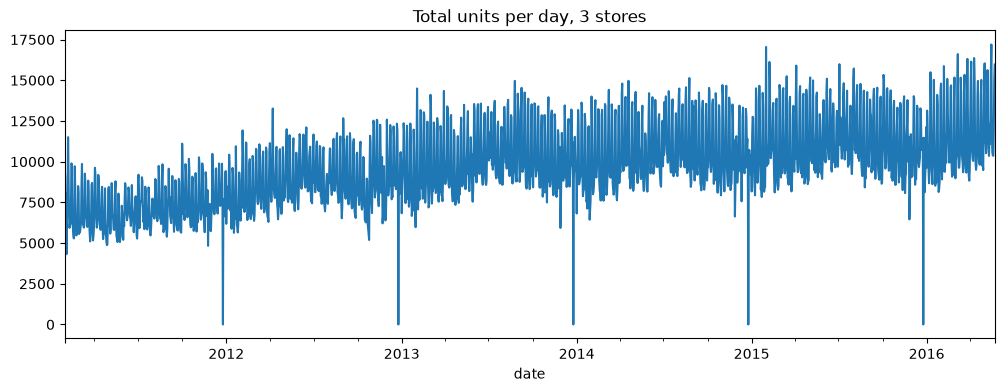

In [33]:
daily = sales[day_cols].sum()
daily.index = calendar.set_index("d").loc[daily.index, "date"]
daily.plot(figsize=(12, 4), title="Total units per day, 3 stores")

On the yearly pattern i see that its almost a stable pattern that has been increasing slightly over the years, but every year there is some remarquable and unusuals dips especially in 2015 the sales increased significally and then dropped.

In [34]:
daily.groupby(daily.index.dayofweek).mean()

date
0     9005.324910
1     8272.555957
2     8239.606498
3     8307.472924
4     9725.909747
5    12204.460432
6    11978.942446
dtype: float64

Now on the weekly pattern we see that its also slightly decreasing by the days of the week till the peak of increasing hits on saturdays and then it decreases back on sundays.So the best selling days are fridays and saturdays

Christmas days 

In [35]:
daily[(daily.index.month == 12) & (daily.index.day == 25)]

date
2011-12-25    0
2012-12-25    0
2013-12-25    2
2014-12-25    0
2015-12-25    3
dtype: int64

In [36]:
for year in range(2011, 2016):
    print(daily[f"{year}-12-23":f"{year}-12-27"])
    print()

date
2011-12-23    9877
2011-12-24    8153
2011-12-25       0
2011-12-26    7677
2011-12-27    6637
dtype: int64

date
2012-12-23    11911
2012-12-24     8913
2012-12-25        0
2012-12-26     8153
2012-12-27     7997
dtype: int64

date
2013-12-23    11222
2013-12-24     9272
2013-12-25        2
2013-12-26     8992
2013-12-27     9810
dtype: int64

date
2014-12-23    11404
2014-12-24     9227
2014-12-25        0
2014-12-26     9806
2014-12-27    10723
dtype: int64

date
2015-12-23    11417
2015-12-24    10566
2015-12-25        3
2015-12-26    11471
2015-12-27    10518
dtype: int64



Most retailers close or nearly close that day, so sales drop sharply.

A zero in the sales data can mean four different things:

no one wanted the item (true zero demand),

the item was not on sale yet;

the store was closed (Christmas),

the shelf was empty (a stockout).

Load prices

In [37]:
prices = pd.read_csv(RAW / "sell_prices.csv")
prices = prices[prices["store_id"].isin(STORES)]
print(prices.shape)
prices.head()

(2064120, 4)


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


(wm_yr_wk = a week id)

If an item has no row for a week, it was not sold in that store that week.

when did each product start being sold?

Some products only arrived in stores after 2011. Before that, their sales are zero, but not because customers didn’t want them. They simply weren’t on the shelf. We call these days “not yet on sale”. This cell finds them :

In [38]:
import numpy as np

sales = sales.reset_index(drop=True)
vals = sales[day_cols].to_numpy()

first_price_wk = (
    prices.groupby(["item_id", "store_id"])["wm_yr_wk"].min()
    .rename("first_price_wk").reset_index()
)
meta = sales[["item_id", "store_id"]].merge(first_price_wk, on=["item_id", "store_id"], how="left")

week_start_day = (
    calendar.assign(d_num=calendar["d"].str[2:].astype(int))
    .groupby("wm_yr_wk")["d_num"].min()
)
meta["first_price_day"] = meta["first_price_wk"].map(week_start_day)

print("series with no price at all:", meta["first_price_day"].isna().sum())
print("share of series that start after day 1:", (meta["first_price_day"] > 1).mean())

day_idx = np.arange(1, len(day_cols) + 1)
first_day = meta["first_price_day"].fillna(len(day_cols) + 1).to_numpy()
not_on_sale = day_idx[None, :] < first_day[:, None]
print("share of item-days before the first price:", not_on_sale.mean())
print("units sold on those days:", vals[not_on_sale].sum())

series with no price at all: 0
share of series that start after day 1: 0.6425057395867497
share of item-days before the first price: 0.20318077953616603
units sold on those days: 0


 Products that start late

- No product is without a price: **0** series have no price at all.
- **64%** of the series (about 6 in 10 products) start after day 1, which means they were introduced in the stores after 29 January 2011.
- **20%** of all item-days happen before the product's first price, so the product was **not yet on sale**.
- On those days, **0 units** were sold. This confirms that these zeros are not demand, they mean "not yet in the store".


Intermittent demand

In [39]:
on_sale = ~not_on_sale
zero_share_all = (vals == 0).mean()
zero_share_on_sale = ((vals == 0) & on_sale).sum() / on_sale.sum()
print("zeros overall:", zero_share_all)
print("zeros when on sale:", zero_share_on_sale)

per_series = ((vals == 0) & on_sale).sum(axis=1) / on_sale.sum(axis=1)
sales["zero_share"] = per_series
sales.groupby("cat_id")["zero_share"].mean()

zeros overall: 0.6774239316421287
zeros when on sale: 0.5951703221088247


C:\Users\bahri\AppData\Local\Temp\ipykernel_31896\66846835.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sales["zero_share"] = per_series


cat_id
FOODS        0.519987
HOBBIES      0.715119
HOUSEHOLD    0.643985
Name: zero_share, dtype: float64

- Share of zero days overall: **67.7%**
- Share of zero days when the product was on sale: **59.5%**
- Zero share by category: **HOBBIES 71.5%** (most zeros), **HOUSEHOLD 64.4%**, **FOODS 52.0%** (fewest zeros).

Even when a product is in the store, it sells nothing on about 6 days out of 10. The 8-point gap between the two numbers (67.7% vs 59.5%) comes from the "not yet on sale" days we found in Question 1. Counting them would have made the demand look weaker than it is.

Hobbies products are slow sellers (they often sell nothing for days), while food products sell more regularly. This is called **intermittent demand**: many zeros and a few days with one or more units. It is harder to forecast than a steady seller, because the average (for example 0.4 units per day) is almost never what actually happens: the real value is usually 0, sometimes 1 or 2.

**Consequences for the project:**
- A forecast must predict a range of likely values (low, medium, high), not only one number.
- Percentage-error metrics such as MAPE break when the true value is 0, so we will use WAPE and pinball loss instead.
- Some of these zeros may be hidden stockouts in the real Walmart data, which is the censored-demand assumption from the charter.

SNAP days

SNAP is a US food-assistance programme, and benefits are paid on certain days of the month, which changes food sales. Each state has its own flag in the calendar.

In [40]:
cal_by_d = calendar.set_index("d")
for store in STORES:
    state = store[:2]
    rows = ((sales["cat_id"] == "FOODS") & (sales["store_id"] == store)).to_numpy()
    units = vals[rows].sum(axis=0)
    snap = cal_by_d.loc[day_cols, f"snap_{state}"].to_numpy()
    print(store, pd.Series(units).groupby(snap).mean().round(1).to_dict())

CA_1 {0: 2712.0, 1: 3036.5}
TX_1 {0: 1869.8, 1: 2199.8}
WI_1 {0: 1772.2, 1: 1893.1}


On SNAP days there's a remarquable increasing on sales. A forecast model that ignores this flag would miss the repeating monthly pattern and under- or over-predict on those days, which leads to wrong stock levels.

In [42]:
import duckdb
duckdb.sql("SELECT COUNT(*) AS days, MIN(date) AS first_day, MAX(date) AS last_day FROM '../data/raw/calendar.csv'")

┌───────┬────────────┬────────────┐
│ days  │ first_day  │  last_day  │
│ int64 │    date    │    date    │
├───────┼────────────┼────────────┤
│  1969 │ 2011-01-29 │ 2016-06-19 │
└───────┴────────────┴────────────┘